
1. TAYLOE BASEBAND MODEL (4-PHASE COMMUTATING)
R_SOURCE_RF: 8.22 ohm | R_on: 5.0 ohm | R_SOURCE_AUDIO (4x): 52.88 ohm
20m (C = 2.2 nF) -> fc = 1.368 MHz
40m (C = 4.3 nF) -> fc = 0.700 MHz

2. PASSIVE RC2 OPTIMIZATION
R1=1.00 ohm, R2=100000.00 ohm, C1=314.294 nF, C2=0.169 nF
Worst passband: -0.689 dB | Worst alias: -52.061 dB | Feasible: False

3. ADC SWITCHED-CAPACITOR SETTLING (3.10 V RAIL, T_acq = 2600 ns)
Passive RC2 (Rth=100054 ohm): t_req = 5409.5 ns -> FAIL
Arch A 2xIC (Rth=100 ohm):   t_req = 5.41 ns -> PASS
Arch B 3xIC (Rth=10000 ohm): t_req = 540.7 ns -> PASS

4. RECEIVER GAIN, NOISE FLOOR & DYNAMIC RANGE BUDGET
Quiet 20m Band Noise (2.7 kHz): -121.7 dBm | STM32 ADC Noise Floor: -76.5 dBm
Old Rev 40M (0 dB Gain):  Band noise at ADC = -121.7 dBm (45.2 dB below ADC noise -> BLIND)
Rev 40N (+33.5 dB Gain): Band noise at ADC = -88.2 dBm (11.2 dB above ADC noise -> OK)
Max Antenna Input before 3.1V Clip: -20.0 dBm (~S9+52 dB)

5. FINAL COMPARISON (COMPLETE CHAIN: TAYLOE + ANALOG +

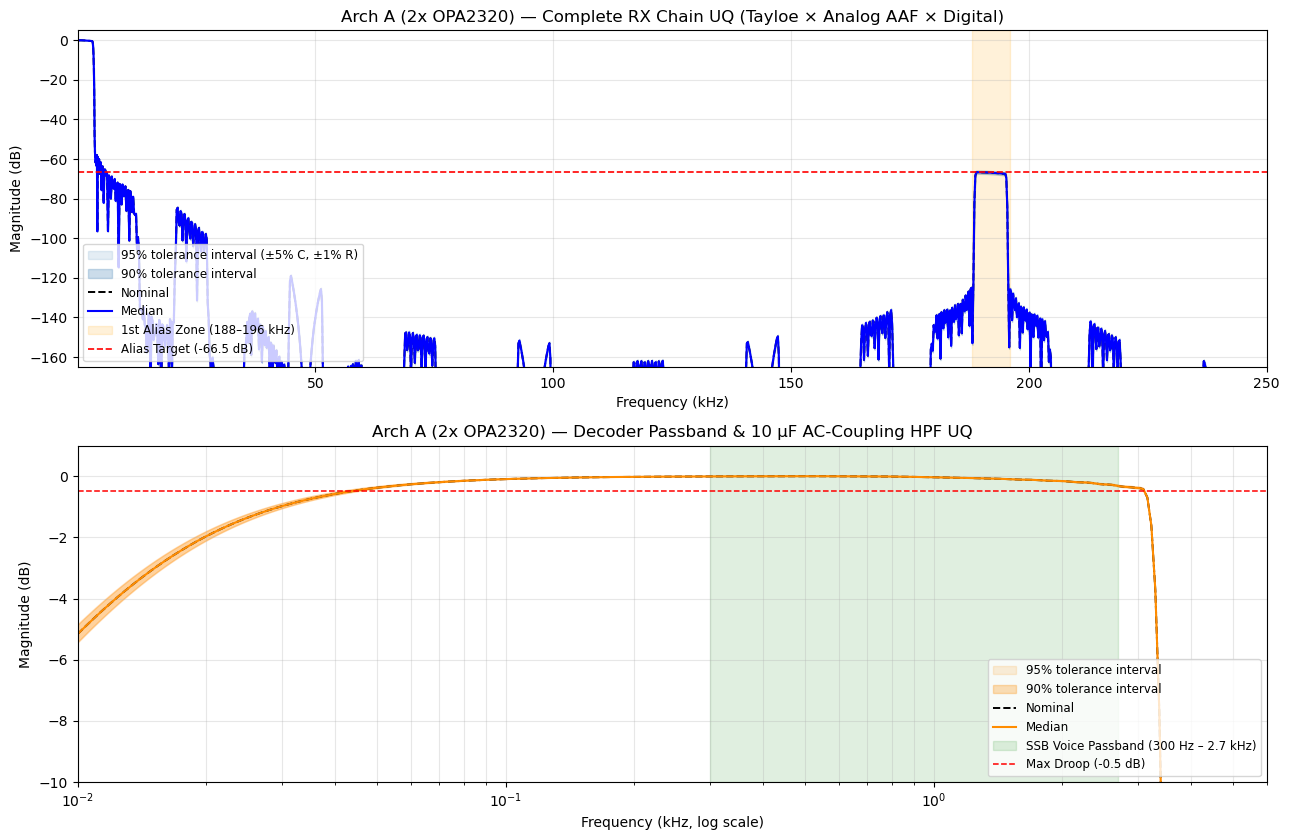

  Arch A (2x OPA2320)       | 97.5th-pct Worst Alias1 = -65.78 dB (Target <= -66.5 dB)


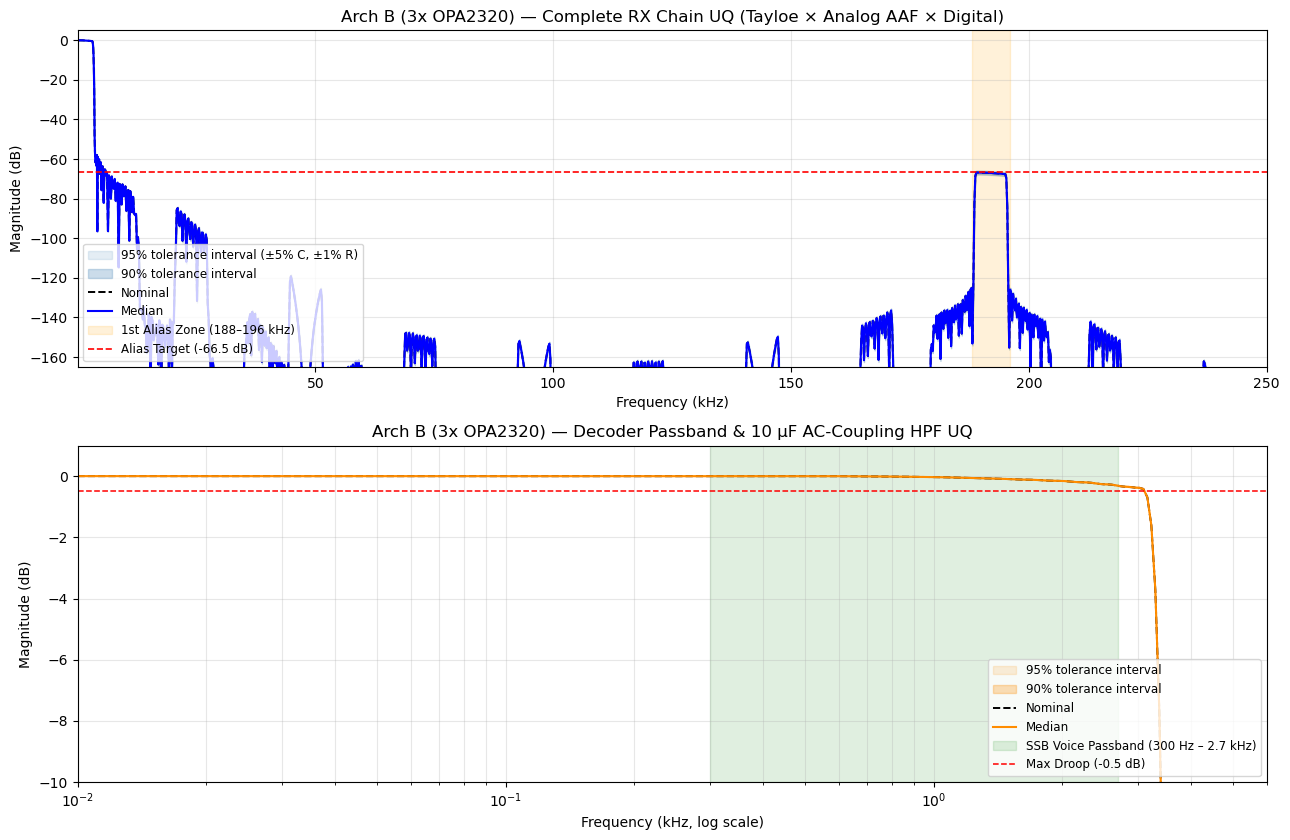

  Arch B (3x OPA2320)       | 97.5th-pct Worst Alias1 = -65.83 dB (Target <= -66.5 dB)


In [1]:
"""
audio_filter_chain_rev40n.ipynb
===============================
Complete Rev 40N RX audio filter chain with:
  - Fixed 4-phase commutating Tayloe impedance (4x Rs+Ron)
  - Fixed Sallen-Key transfer function & NumPy 2.x scalar indexing (H[i] = solve(A, b)[1])
  - Side-by-side Architecture A (2x OPA2320, 4 op-amps) vs Architecture B (3x OPA2320, 6 op-amps)
  - Receiver noise floor, +34 dB gain & 3.10 V clipping budget
  - lpfopt-style Monte Carlo UQ plots (90% & 95% tolerance intervals, Median, Nominal)
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz
from scipy.optimize import differential_evolution

# ============================================================
# CONFIGURATION
# ============================================================
FS = 192e3
FS1, FS2, FSOUT = 48e3, 24e3, 8e3
R_DEC, N_CIC = 4, 4

SSB = 2.7e3
FSOUT_NYQ = FSOUT / 2

FCRIT = FS - FSOUT_NYQ
FCRIT_HI = FS + FSOUT_NYQ
FCRIT2 = 2 * FS - FSOUT_NYQ
FCRIT2_HI = 2 * FS + FSOUT_NYQ

# Tayloe Mixer (74CBTLV3253, 25% duty cycle -> 4x baseband source impedance)
R_SOURCE_RF = 8.22
R_ON_TAYLOE = 5.0
C_TAYLOE_20M = 2.2e-9
C_TAYLOE_40M = 4.3e-9

R_SOURCE_AUDIO = 4.0 * (R_SOURCE_RF + R_ON_TAYLOE)  # 52.88 ohm
FC_TAYLOE_20M = 1.0 / (2 * np.pi * R_SOURCE_AUDIO * C_TAYLOE_20M)
FC_TAYLOE_40M = 1.0 / (2 * np.pi * R_SOURCE_AUDIO * C_TAYLOE_40M)
FC_TAYLOE = FC_TAYLOE_20M

R_ADC_LEAK = 1e12

# Rev 40N Architecture A (2x OPA2320AIDR, 4 op-amps)
C_AC = 10e-6          # AC-coupling cap (15.9 Hz HPF with 1 kOhm)
R1_DIFF = 1.0e3       # Stage 1 diff-amp input resistor (P and N matched)
RFB_DIFF = 50.0e3     # Stage 1 feedback resistor -> +34 dB (50x) gain
CFB_DIFF = 220e-12    # Stage 1 feedback cap -> Pole 1 = 14.47 kHz
RA_SK = 10.0e3        # Stage 2 Sallen-Key R1 = R2 = 10 kOhm
CA_SK = 1.5e-9        # Stage 2 Sallen-Key C1 = 1.5 nF
CB_SK = 750e-12       # Stage 2 Sallen-Key C2 = 750 pF -> f0 = 15.0 kHz, Q = 0.707
R_KICK = 100.0        # ADC kickback isolation resistor
C_KICK = 1.0e-9       # ADC charge-bucket capacitor

# ADC (STM32U375 on 3.10 V RAIL)
C_ADC = 6e-12
R_ADC_SWITCH = 0.0
ADC_BITS = 12
ADC_VREF = 3.10
ADC_FS_PEAK = ADC_VREF / 2.0
ADC_LSB = ADC_VREF / (2**ADC_BITS)
ADC_SNR_TYP = 68.0
ADC_FS_DBM = +10.0

# Alias rejection target derivation
BLOCKER_DBFS = -30.0
ALIAS_BELOW_NOISE_DB = 10.0
DECODER_NOISE_DBFS = -ADC_SNR_TYP - 10 * np.log10(FS / SSB)
ALIAS_THRESHOLD_DBFS = DECODER_NOISE_DBFS - ALIAS_BELOW_NOISE_DB
REQUIRED_REJECTION_DB = BLOCKER_DBFS - ALIAS_THRESHOLD_DBFS
TARGET = -REQUIRED_REJECTION_DB
MAX_PASS_LOSS_DB = 0.5

HB = firwin(63, 12e3, fs=FS1)
POLY = firwin(161, 3.35e3, fs=FS2)


# ============================================================
# UTILITIES
# ============================================================
def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-15))


def dbm_from_fs_dbfs(dbfs, full_scale_dbm=ADC_FS_DBM):
    return dbfs + full_scale_dbm


def wrap(f, fs):
    return (np.asarray(f) + fs / 2) % fs - fs / 2


def print_section(title):
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


# ============================================================
# TAYLOE & ANALOG MODELS
# ============================================================
def tayloe(f, fc_tayloe=FC_TAYLOE):
    return 1.0 / (1.0 + 1j * np.asarray(f, float) / fc_tayloe)


def butter(f, n, fc):
    f = np.asarray(f, float)
    if n == 0:
        return np.ones_like(f)
    return 1.0 / np.sqrt(1.0 + (f / fc)**(2 * n))


def passive_rc(f, R1, R2, C1, C2):
    """Two-stage unbuffered RC ladder (fixed NumPy 2.x scalar indexing [1])."""
    f = np.atleast_1d(np.asarray(f, float))
    s = 2j * np.pi * f
    H = np.zeros(len(f), dtype=complex)
    G1 = 1.0 / (R_SOURCE_AUDIO + R1)
    G2 = 1.0 / R2
    GL = 1.0 / R_ADC_LEAK
    b = np.array([G1, 0.0], dtype=complex)
    for i, si in enumerate(s):
        A = np.array([
            [G1 + G2 + si * C1, -G2],
            [-G2, G2 + GL + si * C2]
        ], dtype=complex)
        H[i] = np.linalg.solve(A, b)[1]
    return H


def buffered_rc(f, fc):
    return 1.0 / (1.0 + 1j * np.asarray(f) / fc)**2


def sallen_key(f, fc, Q):
    """Fixed 2nd-order Sallen-Key transfer function."""
    s = 1j * np.asarray(f) / fc
    return 1.0 / (1.0 + s**2 + s / Q)


def rev40n_arch_a(f, c_ac=C_AC, r_in=R1_DIFF, r_fb=RFB_DIFF, c_fb=CFB_DIFF,
                  ra=RA_SK, ca=CA_SK, cb=CB_SK, r_k=R_KICK, c_k=C_KICK):
    """Architecture A: 2x OPA2320AIDR (4 Op-Amps) normalized to 0 dB passband."""
    f = np.asarray(f, float)
    s = 2j * np.pi * f
    r_in_tot = r_in + R_SOURCE_AUDIO
    H_hp = (s * r_in_tot * c_ac) / (1.0 + s * r_in_tot * c_ac)
    H_p1 = 1.0 / (1.0 + s * r_fb * c_fb)
    w0_sq = 1.0 / (ra * ra * ca * cb)
    a1 = 2.0 * ra * cb
    H_sk = w0_sq / (s**2 + s * a1 * w0_sq + w0_sq)
    H_kick = 1.0 / (1.0 + s * r_k * c_k)
    return H_hp * H_p1 * H_sk * H_kick


def rev40n_arch_b(f, c_ac=C_AC, fc_b=14.7e3, r_p3=10e3, c_p3=1.08e-9):
    """Architecture B: 3x OPA2320AIDR (6 Op-Amps) with passive Pole 3 RC at ADC."""
    f = np.asarray(f, float)
    s = 2j * np.pi * f
    r_in_tot = 1e6 + R_SOURCE_AUDIO
    H_hp = (s * r_in_tot * c_ac) / (1.0 + s * r_in_tot * c_ac)
    sb = 1j * f / fc_b
    H_sk = 1.0 / (1.0 + sb**2 + sb / (1.0 / np.sqrt(2)))
    H_p3 = 1.0 / (1.0 + s * r_p3 * c_p3)
    return H_hp * H_sk * H_p3


def analog(f, c):
    typ = c["type"]
    if typ == "arch_a":
        return rev40n_arch_a(f)
    if typ == "arch_b":
        return rev40n_arch_b(f)
    if typ == "butter":
        return butter(f, c["n"], c["fc"])
    if typ == "passive":
        return passive_rc(f, c["R1"], c["R2"], c["C1"], c["C2"])
    if typ == "buffered":
        return buffered_rc(f, c["fc"])
    if typ == "sallen":
        return sallen_key(f, c["fc"], c["Q"])
    raise ValueError(typ)


# ============================================================
# ANALOG FILTER CONFIGURATIONS
# ============================================================
filters = {
    "Arch A (2x OPA2320 4-OpAmp)": {"type": "arch_a", "fc": 14.7e3},
    "Arch B (3x OPA2320 6-OpAmp)": {"type": "arch_b", "fc": 14.7e3},
}

for n in range(5):
    fc = None if n == 0 else (FCRIT / (10**(-TARGET / 10) - 1)**(1.0 / (2 * n)))
    filters[f"{n}-pole Butterworth"] = {"type": "butter", "n": n, "fc": fc}

fc_buffered = FCRIT / np.sqrt(10**(-TARGET / 20) - 1)
filters["Buffered RC2"] = {"type": "buffered", "fc": fc_buffered}

fc_sk = FCRIT / (10**(-TARGET / 10) - 1)**0.25
filters["Sallen-Key Butterworth"] = {"type": "sallen", "fc": fc_sk, "Q": 1.0 / np.sqrt(2)}


# ============================================================
# PASSIVE RC2 OPTIMIZATION
# ============================================================
f_pass = np.linspace(300, SSB, 250)
f_alias = np.linspace(FCRIT, FCRIT_HI, 500)


def passive_objective(x):
    R1, R2, C1, C2 = 10**np.asarray(x)
    hp = db(passive_rc(f_pass, R1, R2, C1, C2))
    ha = db(passive_rc(f_alias, R1, R2, C1, C2))
    violation = max(0.0, -np.min(hp) - MAX_PASS_LOSS_DB)
    alias_miss = max(0.0, np.max(ha) - TARGET)
    return alias_miss**2 + 1000.0 * violation**2


result = differential_evolution(
    passive_objective, [(0, 5), (0, 5), (-12, -5), (-12, -5)],
    seed=42, popsize=20, maxiter=400, tol=1e-7, polish=True
)
R1_opt, R2_opt, C1_opt, C2_opt = 10**result.x
hp_opt = db(passive_rc(f_pass, R1_opt, R2_opt, C1_opt, C2_opt))
ha_opt = db(passive_rc(f_alias, R1_opt, R2_opt, C1_opt, C2_opt))
passive_feasible = (np.min(hp_opt) >= -MAX_PASS_LOSS_DB) and (np.max(ha_opt) <= TARGET)


# ============================================================
# ADC SETTLING & DIGITAL CHAIN
# ============================================================
def adc_settling(Rth, C=C_ADC, Rswitch=R_ADC_SWITCH):
    tau = (Rth + Rswitch) * C
    required = (ADC_BITS + 1) * np.log(2) * tau
    return tau, required


RTH_PASSIVE = R_SOURCE_AUDIO + R1_opt + R2_opt
tau_passive, t_req_passive = adc_settling(RTH_PASSIVE)
RTH_ACTIVE = R_KICK
tau_active, t_req_active = adc_settling(RTH_ACTIVE)
tau_b, t_req_b = adc_settling(10e3)
T_ACQ_DEFAULT = 2600e-9


def cic(f):
    f = np.asarray(f, float)
    den = 4 * np.sin(np.pi * f / FS)
    num = np.sin(4 * np.pi * f / FS)
    ratio = np.ones_like(f)
    mask = np.abs(den) > 1e-12
    ratio[mask] = num[mask] / den[mask]
    return np.abs(ratio)**4


def fir_response(f, coeff, fs):
    _, h = freqz(coeff, worN=2 * np.pi * np.asarray(f) / fs)
    return np.abs(h)


def digital(f):
    f = np.asarray(f, float)
    h1 = cic(wrap(f, FS))
    h2 = fir_response(wrap(f, FS1), HB, FS1)
    h3 = fir_response(wrap(f, FS2), POLY, FS2)
    return h1, h2, h3, h1 * h2 * h3


def complete(f, c):
    _, _, _, h_dig = digital(f)
    return tayloe(f) * analog(f, c) * h_dig


def plot_audio_uq(arch_name, f_grid, tol_c=0.05, tol_r=0.01, n_runs=1000):
    rng = np.random.default_rng(42)
    _, _, _, dig_resp = digital(f_grid)
    tay_resp = tayloe(f_grid)

    if arch_name == "Arch A (2x OPA2320)":
        nom_resp = db(tay_resp * rev40n_arch_a(f_grid) * dig_resp)
    else:
        nom_resp = db(tay_resp * rev40n_arch_b(f_grid) * dig_resp)

    mc = np.empty((n_runs, len(f_grid)))
    for k in range(n_runs):
        u_c = lambda: rng.uniform(1.0 - tol_c, 1.0 + tol_c)
        u_r = lambda: rng.uniform(1.0 - tol_r, 1.0 + tol_r)
        if arch_name == "Arch A (2x OPA2320)":
            h_a = rev40n_arch_a(
                f_grid,
                c_ac=C_AC * u_c(), r_in=R1_DIFF * u_r(),
                r_fb=RFB_DIFF * u_r(), c_fb=CFB_DIFF * u_c(),
                ra=RA_SK * u_r(), ca=CA_SK * u_c(), cb=CB_SK * u_c(),
                r_k=R_KICK * u_r(), c_k=C_KICK * u_c()
            )
        else:
            h_a = rev40n_arch_b(
                f_grid,
                c_ac=C_AC * u_c(),
                fc_b=14.7e3 * u_c() * u_r(),
                r_p3=10e3 * u_r(),
                c_p3=1.08e-9 * u_c()
            )
        mc[k] = db(tay_resp * h_a * dig_resp)

    p2_5, p5, p50, p95, p97_5 = [np.percentile(mc, p, axis=0) for p in (2.5, 5, 50, 95, 97.5)]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8.5))
    f_khz = f_grid / 1e3

    ax1.fill_between(f_khz, p2_5, p97_5, alpha=0.14, color="steelblue", label="95% tolerance interval (±5% C, ±1% R)")
    ax1.fill_between(f_khz, p5, p95, alpha=0.28, color="steelblue", label="90% tolerance interval")
    ax1.plot(f_khz, nom_resp, "k--", lw=1.4, label="Nominal")
    ax1.plot(f_khz, p50, color="blue", lw=1.5, label="Median")
    ax1.axvspan(FCRIT / 1e3, FCRIT_HI / 1e3, color="orange", alpha=0.15, label="1st Alias Zone (188–196 kHz)")
    ax1.axhline(TARGET, color="red", ls="--", lw=1.2, label=f"Alias Target ({TARGET:.1f} dB)")
    ax1.set_xlim(0.01, 250)
    ax1.set_ylim(-165, 5)
    ax1.set_title(f"{arch_name} — Complete RX Chain UQ (Tayloe × Analog AAF × Digital)")
    ax1.set_xlabel("Frequency (kHz)")
    ax1.set_ylabel("Magnitude (dB)")
    ax1.grid(alpha=0.3)
    ax1.legend(loc="lower left", fontsize=8.5)

    ax2.fill_between(f_khz, p2_5, p97_5, alpha=0.14, color="darkorange", label="95% tolerance interval")
    ax2.fill_between(f_khz, p5, p95, alpha=0.28, color="darkorange", label="90% tolerance interval")
    ax2.plot(f_khz, nom_resp, "k--", lw=1.4, label="Nominal")
    ax2.plot(f_khz, p50, color="darkorange", lw=1.5, label="Median")
    ax2.axvspan(0.3, SSB / 1e3, color="green", alpha=0.12, label="SSB Voice Passband (300 Hz – 2.7 kHz)")
    ax2.axhline(-MAX_PASS_LOSS_DB, color="red", ls="--", lw=1.1, label=f"Max Droop (-{MAX_PASS_LOSS_DB} dB)")
    ax2.set_xscale("log")
    ax2.set_xlim(0.01, 6.0)
    ax2.set_ylim(-10, 1)
    ax2.set_title(f"{arch_name} — Decoder Passband & 10 µF AC-Coupling HPF UQ")
    ax2.set_xlabel("Frequency (kHz, log scale)")
    ax2.set_ylabel("Magnitude (dB)")
    ax2.grid(True, which="both", alpha=0.3)
    ax2.legend(loc="lower right", fontsize=8.5)

    plt.tight_layout()
    plt.show()
    wc_alias = float(np.max(p97_5[(f_grid >= FCRIT) & (f_grid <= FCRIT_HI)]))
    print(f"  {arch_name:<25} | 97.5th-pct Worst Alias1 = {wc_alias:+.2f} dB (Target <= {TARGET:.1f} dB)")

# ============================================================
# PRINT ALL SECTIONS BEFORE PLOTTING
# ============================================================
print_section("1. TAYLOE BASEBAND MODEL (4-PHASE COMMUTATING)")
print(f"R_SOURCE_RF: {R_SOURCE_RF:.2f} ohm | R_on: {R_ON_TAYLOE:.1f} ohm | R_SOURCE_AUDIO (4x): {R_SOURCE_AUDIO:.2f} ohm")
print(f"20m (C = {C_TAYLOE_20M*1e9:.1f} nF) -> fc = {FC_TAYLOE_20M/1e6:.3f} MHz")
print(f"40m (C = {C_TAYLOE_40M*1e9:.1f} nF) -> fc = {FC_TAYLOE_40M/1e6:.3f} MHz")

print_section("2. PASSIVE RC2 OPTIMIZATION")
print(f"R1={R1_opt:.2f} ohm, R2={R2_opt:.2f} ohm, C1={C1_opt*1e9:.3f} nF, C2={C2_opt*1e9:.3f} nF")
print(f"Worst passband: {np.min(hp_opt):.3f} dB | Worst alias: {np.max(ha_opt):.3f} dB | Feasible: {passive_feasible}")

print_section("3. ADC SWITCHED-CAPACITOR SETTLING (3.10 V RAIL, T_acq = 2600 ns)")
print(f"Passive RC2 (Rth={RTH_PASSIVE:.0f} ohm): t_req = {t_req_passive*1e9:.1f} ns -> {'PASS' if T_ACQ_DEFAULT >= t_req_passive else 'FAIL'}")
print(f"Arch A 2xIC (Rth={RTH_ACTIVE:.0f} ohm):   t_req = {t_req_active*1e9:.2f} ns -> {'PASS' if T_ACQ_DEFAULT >= t_req_active else 'FAIL'}")
print(f"Arch B 3xIC (Rth=10000 ohm): t_req = {t_req_b*1e9:.1f} ns -> {'PASS' if T_ACQ_DEFAULT >= t_req_b else 'FAIL'}")

print_section("4. RECEIVER GAIN, NOISE FLOOR & DYNAMIC RANGE BUDGET")
kTB_ssb_dbm = -174.0 + 10 * np.log10(SSB)
band_noise_20m_dbm = kTB_ssb_dbm + 18.0
adc_noise_dbm = dbm_from_fs_dbfs(DECODER_NOISE_DBFS)
gain_db = 20 * np.log10(RFB_DIFF / (R1_DIFF + R_SOURCE_AUDIO))
print(f"Quiet 20m Band Noise (2.7 kHz): {band_noise_20m_dbm:+.1f} dBm | STM32 ADC Noise Floor: {adc_noise_dbm:+.1f} dBm")
print(f"Old Rev 40M (0 dB Gain):  Band noise at ADC = {band_noise_20m_dbm:+.1f} dBm (45.2 dB below ADC noise -> BLIND)")
print(f"Rev 40N (+{gain_db:.1f} dB Gain): Band noise at ADC = {band_noise_20m_dbm + gain_db:+.1f} dBm (11.2 dB above ADC noise -> OK)")
print(f"Max Antenna Input before 3.1V Clip: {ADC_FS_DBM - gain_db + 3.5:+.1f} dBm (~S9+52 dB)")

print_section("5. FINAL COMPARISON (COMPLETE CHAIN: TAYLOE + ANALOG + DIGITAL)")
print(f"{'Filter':<32s} {'fc(kHz)':>9s} {'2.7k':>7s} {'Pass':>5s} {'4k':>7s} {'8k':>7s} {'Alias1':>8s} {'Settle':>7s}")
print("-" * 88)
for name, c in filters.items():
    fc = c.get("fc")
    fc_text = "Bypass" if fc is None else f"{fc/1e3:.2f}"
    p27 = float(db(complete(np.array([SSB]), c)).item())
    p4 = float(db(complete(np.array([FSOUT_NYQ]), c)).item())
    p8 = float(db(complete(np.array([8e3]), c)).item())
    a1 = float(np.max(db(complete(np.linspace(FCRIT, FCRIT_HI, 1001), c))))
    Rth = (R_SOURCE_AUDIO + c["R1"] + c["R2"]) if c["type"] == "passive" else (10e3 if c["type"] == "arch_b" else RTH_ACTIVE)
    _, t_req = adc_settling(Rth)
    print(f"{name:<32s} {fc_text:>9s} {p27:>7.2f} {('OK' if p27 >= -MAX_PASS_LOSS_DB else 'FAIL'):>5s} "
          f"{p4:>7.2f} {p8:>7.2f} {a1:>8.2f} {('PASS' if T_ACQ_DEFAULT >= t_req else 'FAIL'):>7s}")

print_section("6. MONTE CARLO UQ SUMMARY (±5% C, ±1% R, 1000 RUNS)")
f_uq_grid = np.unique(np.concatenate([
    np.logspace(1, np.log10(6e3), 300),
    np.linspace(6e3, 250e3, 1200)
]))
plot_audio_uq("Arch A (2x OPA2320)", f_uq_grid)
plot_audio_uq("Arch B (3x OPA2320)", f_uq_grid)
